# Рекомендации Amazon Musical Instruments 2018

Светлов Иван Ильич

Пять моделей с нуля: ItemKNN, ALS для явных оценок, EASE, FM с метапризнаками и timeSVD++.
Ещё сравниваются популярные товары, FM только с ID и SVD++ без времени.

## Запуск

Python 3.12, процессор, желательно 16 ГБ памяти. Из корня репозитория:

```bash
cd hw1
python -m pip install -r requirements.txt
python -m pip install --no-deps --no-build-isolation -e .
python scripts/execute_notebook.py
```

Ноутбук можно выполнять и по ячейкам в Jupyter. Данные скачиваются из первоисточника.
Первый запуск выполняет весь поиск и обучение, это дольше просмотра готовых результатов.
Повторный запуск использует только завершённые совместимые этапы.
Выводы ячеек сохранены в этом файле. Данные и веса в Git не входят.

In [1]:
from pathlib import Path
import os, sys, json, random, gc, subprocess, inspect
ROOT = Path.cwd().resolve()
if not (ROOT / 'models').is_dir():
    ROOT = ROOT / 'hw1'
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / 'src')]
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'artifacts/matplotlib'))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from threadpoolctl import threadpool_limits
from recsys.experiment import Experiment, configure_runtime
from recsys.data import prepare, load_dataset
from recsys.download import download_ratings, fetch, METADATA_URL, METADATA_SHA256, prepare_metadata
from recsys.io import sha256
from models.itemknn import ItemKNN
from models.als import ExplicitALS
from models.ease import EASE
from models.fm import FM
from models.timesvd import TimeSVDPP
%matplotlib inline
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
configure_runtime(4)
config = json.loads(Path('configs/benchmark.json').read_text(encoding='utf-8'))
PRIMARY_METRIC = 'ndcg@10'
K = 10
DATA = Path('data/prepared')
RUNS = Path('artifacts/hw1')
REPORT = Path('reports')
pd.set_option('display.max_colwidth', 180)
print('Основная метрика:', PRIMARY_METRIC, 'K:', K)
print('Начальные значения генераторов:', config['seeds'])
print('Python:', sys.version.split()[0], 'NumPy:', np.__version__, 'PyTorch:', torch.__version__)

Основная метрика: ndcg@10 K: 10
Начальные значения генераторов: [17, 42, 2026]
Python: 3.12.14 NumPy: 2.5.4 PyTorch: 2.14.1+cpu


## 1. Данные и задача

[Amazon Review Data 2018, UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/), категория Musical Instruments.
Используются полный [файл оценок](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments.csv)
и [метаданные товаров](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Musical_Instruments.json.gz).

| Поле | Смысл |
|---|---|
| item_id | ASIN товара |
| user_id | Идентификатор автора отзыва |
| rating | Оценка от 1 до 5 |
| timestamp | Время отзыва в секундах UTC |
| title, brand, categories | Название, бренд и категории из отдельного файла |

Один отзыв считается наблюдаемым взаимодействием. Время покупки неизвестно.
Рекомендуются 10 ещё не оценённых пользователем товаров.
Релевантный товар имеет будущую оценку не ниже 4. Для товаров без отзыва предпочтение неизвестно.
Этот критерий одинаков для всех моделей, хотя цели обучения у них разные.

In [2]:
raw_path = download_ratings(Path('data/raw'))
meta_path = Path('data/raw/meta_Musical_Instruments.json.gz')
fetch(METADATA_URL, meta_path, METADATA_SHA256)
raw = pd.read_csv(raw_path, header=None, names=['item_id', 'user_id', 'rating', 'timestamp'],
                  dtype={'item_id': 'string', 'user_id': 'string'})
raw_shape = {'Взаимодействия': len(raw), 'Пользователи': raw.user_id.nunique(), 'Товары': raw.item_id.nunique()}
display(pd.DataFrame([raw_shape], index=['Исходный файл']))
print('SHA256 оценок:', sha256(raw_path))
print('Период:', pd.to_datetime(raw.timestamp.min(), unit='s', utc=True).date(),
      pd.to_datetime(raw.timestamp.max(), unit='s', utc=True).date())

,Взаимодействия,Пользователи,Товары
Исходный файл,1512530,903330,112222


SHA256 оценок: 8933b17434e4984bcce8cf4ec43d847e0af6aa6d46add28bbb37b80e06da1b06
Период: 2000-01-05 2018-10-04


## 2. Анализ и подготовка

Сначала проверяются пропуски и допустимые оценки. Повторы пары пользователь-товар удаляются,
остаётся первый отзыв по времени. При совпадении дат берётся меньший номер исходной строки.
Все события одного дня остаются вместе, так как более точного времени нет.

,Пропуски
item_id,0
user_id,0
rating,0
timestamp,0


Недопустимые строки: 0


Полные дубликаты: 39241


Повторы пары пользователь-товар: 41966
Все даты имеют точность до дня: True


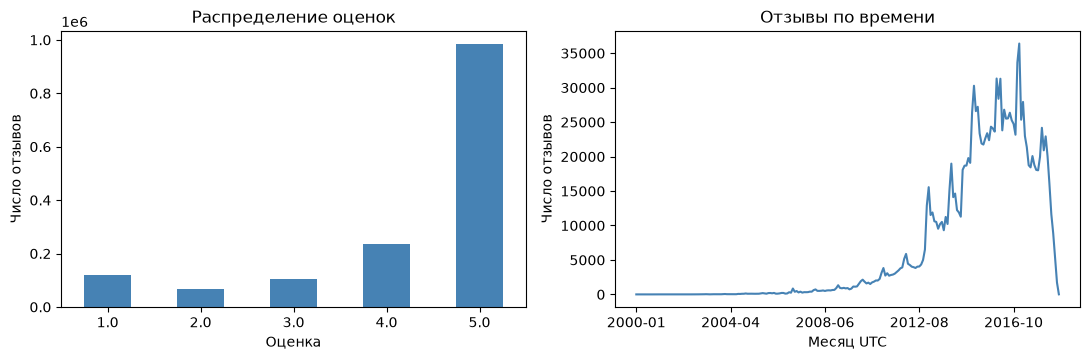

In [3]:
missing = raw.isna().sum().rename('Пропуски').to_frame()
display(missing)
invalid = raw.isna().any(axis=1) | ~raw.rating.isin([1, 2, 3, 4, 5]) | (raw.timestamp < 0)
print('Недопустимые строки:', int(invalid.sum()))
print('Полные дубликаты:', int(raw.duplicated().sum()))
print('Повторы пары пользователь-товар:', int(raw.duplicated(['user_id', 'item_id']).sum()))
print('Все даты имеют точность до дня:', bool((raw.timestamp % 86400 == 0).all()))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
raw.rating.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, color='steelblue')
axes[0].set(xlabel='Оценка', ylabel='Число отзывов', title='Распределение оценок')
months = pd.to_datetime(raw.timestamp, unit='s', utc=True).dt.strftime('%Y-%m')
months.value_counts().sort_index().plot(ax=axes[1], color='steelblue')
axes[1].set(xlabel='Месяц UTC', ylabel='Число отзывов', title='Отзывы по времени')
plt.tight_layout()
plt.show()

Пользователи и товары с совсем короткой историей дают мало информации соседским моделям.
Поэтому после временного разбиения только в обучающей части по очереди удаляются пользователи
и товары с менее чем пятью взаимодействиями. Отбор повторяется до устойчивого состава.
Полученные ID фиксируются для остальных частей. Будущая активность на этот отбор не влияет.

In [4]:
manifest = prepare(raw_path, DATA)
data = load_dataset(DATA)
prepare_metadata(meta_path, data.items, DATA)
metadata = pd.read_csv(DATA / 'metadata.csv').fillna('')
parts = {'Обучение': data.train, 'Проверка': data.validation, 'Тест': data.test}
volume = pd.DataFrame([
    {'Часть': name, 'Взаимодействия': len(frame), 'Пользователи': frame.user.nunique(),
     'Товары': frame.item.nunique(), 'Положительные оценки': int((frame.rating >= 4).sum())}
    for name, frame in parts.items()
]).set_index('Часть')
display(volume)
print('Итого:', sum(map(len, parts.values())), 'взаимодействий,', len(data.users), 'пользователей,', len(data.items), 'товаров')
assert 100_000 <= sum(map(len, parts.values())) <= 2_000_000
assert len(data.users) >= 1000 and len(data.items) >= 1000
display(data.train.head())
del raw, months
gc.collect()

,Взаимодействия,Пользователи,Товары,Положительные оценки
Часть,,,,
Обучение,144036,17702,7329,125702
Проверка,5547,2613,2551,4710
Тест,3741,1985,1938,3094


Итого: 153324 взаимодействий, 17702 пользователей, 7329 товаров


,user,item,rating,timestamp
0,924,5,4.0,1086048000
1,924,38,5.0,1086048000
2,7702,151,4.0,1090281600
3,7702,2885,4.0,1091059200
4,2925,851,5.0,1092960000


52

,Отзывы пользователя,Отзывы товара
count,17702.000000,7329.000000
mean,8.136708,19.652886
std,5.597527,54.173954
min,5.000000,5.000000
25%,5.000000,6.000000
50%,6.000000,9.000000
75%,9.000000,17.000000
max,192.000000,1451.000000


Заполнено 0.1110% обучающей матрицы. Разреженность 99.8890%


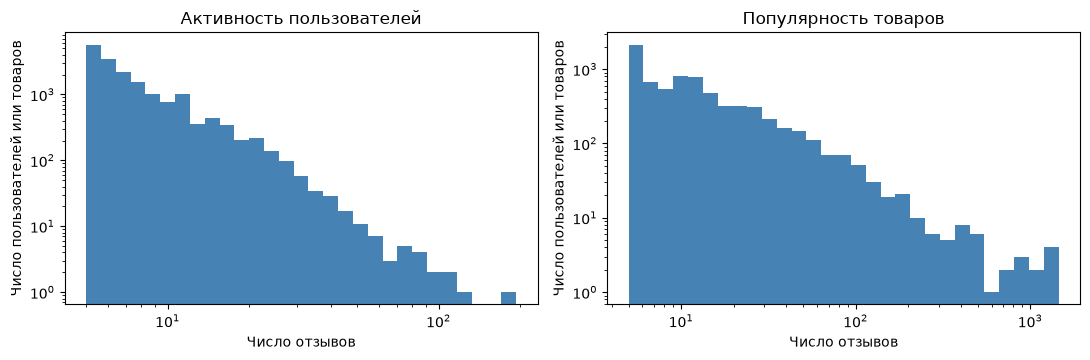

In [5]:
user_activity = data.train.groupby('user').size()
item_popularity = data.train.groupby('item').size()
display(pd.DataFrame({'Отзывы пользователя': user_activity.describe(), 'Отзывы товара': item_popularity.describe()}))
filled = len(data.train) / (len(data.users) * len(data.items))
print(f'Заполнено {filled:.4%} обучающей матрицы. Разреженность {1-filled:.4%}')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, values, title in zip(axes, [user_activity, item_popularity], ['Активность пользователей', 'Популярность товаров']):
    ax.hist(values, bins=np.geomspace(5, max(values.max(), 6)+1, 30), color='steelblue')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set(xlabel='Число отзывов', ylabel='Число пользователей или товаров', title=title)
plt.tight_layout()
plt.show()

Большая часть матрицы пустая, а активность неравномерная.
Данные остаются разреженными и после отбора. Поэтому пропуски нельзя просто считать плохими оценками.

Метаданные присоединяются слева. Отсутствие названия или бренда не удаляет взаимодействие.
Каталожный файл собран позднее части отзывов. Названия используются для показа рекомендаций,
а для FM берутся признаки, которые можно посчитать по прошлой истории.

,Пустые поля
title,5
brand,60
categories,181


,asin,title,brand,categories
0,0739079891,"Alfreds Teach Yourself to Play Ukulele, Complete Starter Pack",Alfred Music Publishing,"[""Musical Instruments"", ""Ukuleles, Mandolins &amp; Banjos"", ""Ukuleles""]"
1,1480360295,"ChordBuddy Guitar Learning System for Right Handed Guitars. Includes ChordBuddy, 2 Month Lesson Plan DVD and Song Book",ChordBuddy,"[""Musical Instruments"", ""Instrument Accessories"", ""Guitar &amp; Bass Accessories""]"
2,9792372326,"QSC K10 2-Way Powered Speaker - 1000 Watts, 1x10""",QSC,"[""Musical Instruments"", ""Live Sound &amp; Stage"", ""Monitors, Speakers &amp; Subwoofers"", ""Speakers"", ""Powered Cabinets""]"
3,B00000J50W,Music Maker - Hand Made Lap Harp - Easy to Play Musical Instrument,Music Maker,"[""Musical Instruments"", ""Band & Orchestra"", ""Orchestral Strings"", ""Harps""]"
4,B00001W0DH,Sony MDR-V700DJ DJ-Style Monitor Series Headphones (Old Version),Sony,"[""Musical Instruments"", ""Studio Recording Equipment"", ""Headphone & In-Ear Audio Monitors"", ""Headphones""]"


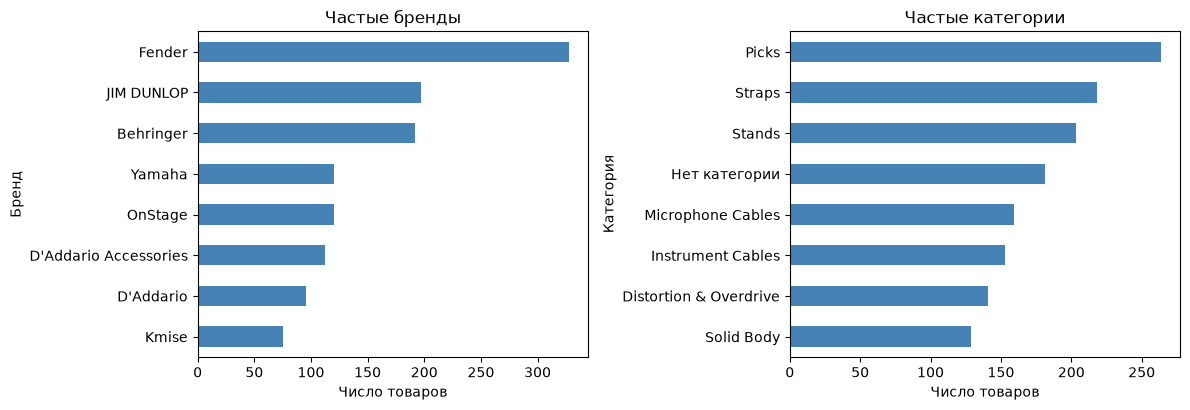

In [6]:
def categories(value):
    result = []
    def visit(x):
        if isinstance(x, list):
            for item in x:
                visit(item)
        elif x:
            result.append(str(x))
    visit(json.loads(value) if value else [])
    return result
meta_missing = pd.Series({col: int(metadata[col].eq('').sum()) for col in ['title', 'brand']}, name='Пустые поля')
meta_categories = metadata.categories.map(categories)
meta_missing.loc['categories'] = int(meta_categories.map(len).eq(0).sum())
display(meta_missing.to_frame())
display(metadata[['asin', 'title', 'brand', 'categories']].head())
leaf = meta_categories.map(lambda x: x[-1] if x else 'Нет категории')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
metadata.brand.replace('', 'Нет бренда').value_counts().head(8).sort_values().plot.barh(ax=axes[0], color='steelblue')
leaf.value_counts().head(8).sort_values().plot.barh(ax=axes[1], color='steelblue')
axes[0].set_title('Частые бренды')
axes[1].set_title('Частые категории')
axes[0].set_ylabel('Бренд')
axes[1].set_ylabel('Категория')
for ax in axes:
    ax.set_xlabel('Число товаров')
plt.tight_layout()
plt.show()

## 3. Протокол оценки

Границы выбраны до обучения по 80-му и 90-му процентилям времени полной категории после удаления повторов.

| Часть | Период UTC |
|---|---|
| Обучение | До 2017-04-17 |
| Проверка | С 2017-04-17 до 2017-12-08 |
| Тест | С 2017-12-08 до конца данных |

Для пользователя ранжируется весь фиксированный каталог из 7 329 товаров за вычетом всех уже оценённых,
включая оценки 1, 2 и 3. Рекомендация выдаётся на начало периода. События внутри периода не добавляются в историю.
Одинаковые оценки разрешаются по меньшему ID товара. Все модели используют одни и те же списки пользователей и кандидатов.

В основную оценку входят пользователи с положительными будущими оценками внутри каталога.
Новые пользователи и товары, а также ID вне отбора по обучающей части в основную таблицу не входят.
Это сравнение для активных пользователей и известного каталога, качество нового пользователя оно не измеряет.
Если у выбранного пользователя нет персонального сигнала, ему предлагаются популярные товары, и он остаётся в метриках.
Дополнительный Recall_all_future@10 включает товары вне каталога в знаменатель и пользователей с положительными отзывами только вне него.

До подбора основной метрикой выбран NDCG@10. Первые места списка важнее последних, поэтому учитывается позиция попадания.
Recall@10 показывает, какую долю положительных будущих товаров удалось найти в десяти рекомендациях.
Также считаются Precision@10 и MAP@10. Все метрики усредняются по пользователям с непустым множеством релевантных товаров.

Для бинарной релевантности: DCG@10 = Σ h_j / log₂(j+1), NDCG@10 = DCG@10 / IDCG@10.
Recall@10 = число попаданий / число релевантных товаров. Precision@10 = число попаданий / 10.
AP@10 = Σ h_j Precision@j / min(10, число релевантных товаров), MAP это среднее AP.

In [7]:
train_snapshot = data.snapshot('validation')
test_snapshot = data.snapshot('test')
assert data.train.timestamp.max() < data.validation_start
assert data.validation.timestamp.min() >= data.validation_start
assert data.validation.timestamp.max() < data.test_start
assert data.test.timestamp.min() >= data.test_start
assert not pd.concat(parts.values()).duplicated(['user', 'item']).any()
display(pd.DataFrame([
    {'Часть': {'validation':'Проверка', 'test':'Тест'}[split], 'Основная группа': len(data.evaluation_users(split)),
     'С учётом товаров вне каталога': len(data.evaluation_users(split, include_outside=True))}
    for split in ['validation', 'test']
]))
display(pd.DataFrame(manifest['exclusions']).T)
print('Правила времени и уникальности пар проверены')

,Часть,Основная группа,С учётом товаров вне каталога
0,Проверка,2330,3127
1,Тест,1702,2493


,outside_user_cohort_rows,outside_item_cohort_rows,outside_either_cohort_rows,selected_users_all_catalog_events,selected_users_outside_catalog_positive_rows,selected_users_positive_only_outside_catalog,positive_event_catalog_coverage
validation,138234,64718,141786,"{'rows': 9099, 'users': 3453, 'items': 5688, 'positive_rows': 7707, 'positive_users': 3127}",2997,797,0.611133
test,140063,68512,142848,"{'rows': 6526, 'users': 2851, 'items': 4359, 'positive_rows': 5393, 'positive_users': 2493}",2299,791,0.573707


Правила времени и уникальности пар проверены


## 4. Модели и подбор параметров

Код обучения и предсказания находится в отдельных файлах `models/`.

| Модель | Оценка и цель |
|---|---|
| ItemKNN | Косинусное сходство положительных историй со сглаживанием n_ij/(n_ij+gamma). Оценка X_u W, диагональ связей нулевая |
| ALS | r̂_ui = μ + b_u + b_i + p_uᵀq_i. Сумма квадратов ошибок по наблюдаемым оценкам и L2. Поочерёдно решаются задачи для пользователей и товаров |
| EASE | min ||X-XB||² + λ||B||² при diag(B)=0. P=(XᵀX+λI)⁻¹, B_ij=-P_ij/P_jj для i≠j |
| FM | w₀+Σw_jx_j+½Σ_f[(Σ_jv_jfx_j)²-Σ_jv_jf²x_j²]. Средняя ошибка квадратов и средний квадрат параметров |
| timeSVD++ | К смещениям и факторам добавлены интервалы времени товара, изменение предпочтений пользователя, дневные поправки и сумма векторов прошлой истории |

У timeSVD++ d_u(t)=sign(t-mean_time_u)|t-mean_time_u|^β, β=0,4.
h_u(t)=Σ y_j/√|H_u(<t)|. В историю входят только предыдущие дни.
Прогноз: μ+b_i+b_i,bin(t)+b_u+α_ud_u(t)+b_u,day(t)+q_iᵀ[p_u+a_ud_u(t)+p_u,day(t)+h_u(t)].
Неизвестные дневные поправки и интервалы товара равны нулю.

FM использует ID, логарифмы количества прошлых отзывов пользователя и товара, их средние оценки,
возраст истории и месяц с днём недели запроса. Эти признаки описывают активность и склонность ставить высокие оценки.
Данные текущего дня не входят в свои агрегаты. Для пустой истории число и возраст равны нулю, средняя оценка равна 3.
Масштабирование настраивается только по обучающим данным. Снимок названий, брендов и категорий в признаки не входит.

MostPopular нужен как простой ориентир. FM только с ID проверяет пользу метапризнаков.
SVD++ с отключённым временем проверяет вклад временных компонентов. Их параметры берутся у полной модели,
но число эпох выбирается отдельно на проверочной части.

In [8]:
classes = {'knn': ItemKNN, 'als': ExplicitALS, 'ease': EASE, 'fm': FM, 'timesvd': TimeSVDPP}
display(pd.DataFrame([{'Модель': name, 'Файл': str(Path(inspect.getfile(cls)).relative_to(ROOT))}
                      for name, cls in classes.items()]))
search_space = pd.DataFrame([
    ['ItemKNN', 'k: 20,50,100,200. gamma: 0,10,50,100', 16],
    ['EASE', 'lambda: 1,3,10,30,100,300,1000,3000', 8],
    ['ALS', 'Размерность 16/32/64. L2 от 0.01 до 100 по логарифмической шкале. До 40 итераций', 16],
    ['FM', 'Размерность 16/32/64. Шаг от 1e-4 до 1e-2, L2 от 1e-6 до 1e-1. До 50 эпох', 16],
    ['timeSVD++', 'Как FM, плюс временной штраф и интервалы 30/90 дней', 16],
    ['MostPopular', 'Без подбора', 1],
], columns=['Модель', 'Пространство поиска', 'Наборы'])
display(search_space)
print('Точные наборы сохранены в configs/benchmark.json')
print('Начальное значение генератора поиска 2026, обучения при подборе', config['tuning_seed'])
print('Остановка после', config['patience'], 'проверок без улучшения. Основная метрика:', PRIMARY_METRIC)

,Модель,Файл
0,knn,models\itemknn.py
1,als,models\als.py
2,ease,models\ease.py
3,fm,models\fm.py
4,timesvd,models\timesvd.py


,Модель,Пространство поиска,Наборы
0,ItemKNN,"k: 20,50,100,200. gamma: 0,10,50,100",16
1,EASE,"lambda: 1,3,10,30,100,300,1000,3000",8
2,ALS,Размерность 16/32/64. L2 от 0.01 до 100 по логарифмической шкале. До 40 итераций,16
3,FM,"Размерность 16/32/64. Шаг от 1e-4 до 1e-2, L2 от 1e-6 до 1e-1. До 50 эпох",16
4,timeSVD++,"Как FM, плюс временной штраф и интервалы 30/90 дней",16
5,MostPopular,Без подбора,1


Точные наборы сохранены в configs/benchmark.json
Начальное значение генератора поиска 2026, обучения при подборе 42
Остановка после 5 проверок без улучшения. Основная метрика: ndcg@10


Ниже выполняется весь заданный поиск. При наличии сохранённого завершённого запуска проверяются
параметры, данные, исходники и окружение. Несовместимый результат не используется.
Тестовые метрики при подборе не считаются.

In [9]:
with threadpool_limits(limits=config['threads']):
    experiment = Experiment(DATA, Path('configs/benchmark.json'), RUNS)
    selected = experiment.tune()

Tune popular 1/1


Tune knn 1/16


Tune knn 2/16


Tune knn 3/16


Tune knn 4/16


Tune knn 5/16


... (63 outputs left out)

Tune timesvd 13/16


Tune timesvd 14/16


Tune timesvd 15/16


Tune timesvd 16/16


,Модель,Параметры,Лучшая эпоха,NDCG@10 на проверке
0,popular,{},1,0.017115
1,knn,"{""k"": 200, ""gamma"": 100}",1,0.023844
2,als,"{""rank"": 64, ""reg"": 7.346387132242643, ""bias_reg"": 70.61198153818842, ""epochs"": 40}",8,0.011582
3,ease,"{""reg"": 3000}",1,0.023618
4,fm,"{""rank"": 16, ""lr"": 0.00016652256321245668, ""reg"": 0.012128490832219785, ""epochs"": 50, ""batch_size"": 4096}",1,0.017572
5,timesvd,"{""rank"": 16, ""lr"": 0.0005649530690262978, ""reg"": 5.529444366780938e-06, ""temporal_reg"": 0.06224758489300692, ""epochs"": 50, ""bin_days"": 90, ""batch_size"": 4096}",1,0.013665


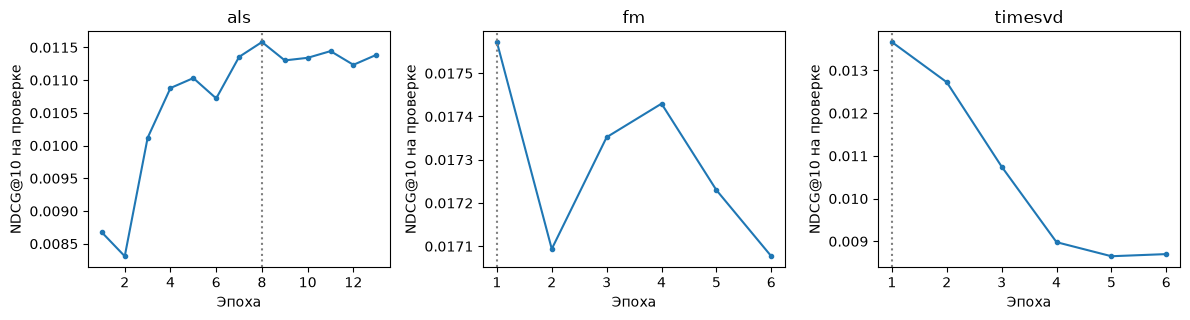

In [10]:
chosen = pd.DataFrame([
    {'Модель': name, 'Параметры': json.dumps(row['parameters'], ensure_ascii=False),
     'Лучшая эпоха': row['best_epoch'], 'NDCG@10 на проверке': row['validation'][PRIMARY_METRIC]}
    for name, row in selected.items()
])
display(chosen)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, name in zip(axes, ['als', 'fm', 'timesvd']):
    trial = json.loads((RUNS / 'trials' / name / f"{selected[name]['trial']:03d}.json").read_text())
    curve = pd.DataFrame(trial['curve'])
    ax.plot(curve.epoch, curve.ndcg, marker='o', markersize=3)
    ax.axvline(selected[name]['best_epoch'], linestyle=':', color='gray')
    ax.set(title=name, xlabel='Эпоха', ylabel='NDCG@10 на проверке')
plt.tight_layout()
plt.show()

## 5. Итоговое сравнение при K = 10

Настройки уже выбраны. Каждая случайная модель ещё раз выбирает число эпох для своего начального
значения генератора на проверочной части. Потом обучается на обучающей и проверочной частях вместе.
Тест используется только для итогового сравнения.

In [11]:
with threadpool_limits(limits=config['threads']):
    experiment.final()
from recsys.report import build_report
build_report(DATA, RUNS, REPORT)
subprocess.run([sys.executable, 'scripts/plot_tradeoff.py', str(REPORT)], check=True)
subprocess.run([sys.executable, 'scripts/verify_report.py', str(REPORT)], check=True)

CompletedProcess(args=['C:\\Users\\Svetlov\\Documents\\ChatGPT\\Учеба\\recsys-musical-instruments\\.venv\\Scripts\\python.exe', 'scripts/verify_report.py', 'reports'], returncode=0)

,Модель,Запуски,NDCG@10,Отклонение NDCG,Recall@10,Precision@10,MAP@10,Покрытие каталога,Параметры
0,MostPopular,1,0.012757,0.000000,0.018221,0.006639,0.009449,0.003002,{}
1,ItemKNN,1,0.012816,0.000000,0.020066,0.005288,0.008397,0.321599,"{""k"": 200, ""gamma"": 100}"
2,ALS,3,0.009521,0.001118,0.014795,0.003604,0.006367,0.037295,"{""rank"": 64, ""reg"": 7.346387132242643, ""bias_reg"": 70.61198153818842, ""epochs"": 8}"
3,EASE,1,0.014113,0.000000,0.025069,0.005699,0.008449,0.142721,"{""reg"": 3000}"
4,FM с признаками,3,0.013232,0.000603,0.018933,0.006796,0.009429,0.003275,"{""rank"": 16, ""lr"": 0.00016652256321245668, ""reg"": 0.012128490832219785, ""epochs"": 1, ""batch_size"": 4096}"
5,timeSVD++,3,0.008831,0.001153,0.012786,0.004093,0.005188,0.054578,"{""rank"": 16, ""lr"": 0.0005649530690262978, ""reg"": 5.529444366780938e-06, ""temporal_reg"": 0.06224758489300692, ""epochs"": 1, ""bin_days"": 90, ""batch_size"": 4096}"
6,FM только ID,3,0.012768,0.000526,0.018559,0.006424,0.008827,0.003866,"{""rank"": 16, ""lr"": 0.00016652256321245668, ""reg"": 0.012128490832219785, ""epochs"": 4, ""batch_size"": 4096}"
7,SVD++ без времени,3,0.010974,0.001589,0.016569,0.005405,0.007139,0.012917,"{""rank"": 16, ""lr"": 0.0005649530690262978, ""reg"": 5.529444366780938e-06, ""temporal_reg"": 0.06224758489300692, ""epochs"": 6, ""bin_days"": 90, ""batch_size"": 4096}"


Число эпох в параметрах показано для начального значения генератора 42. Для остальных запусков оно выбирается отдельно.


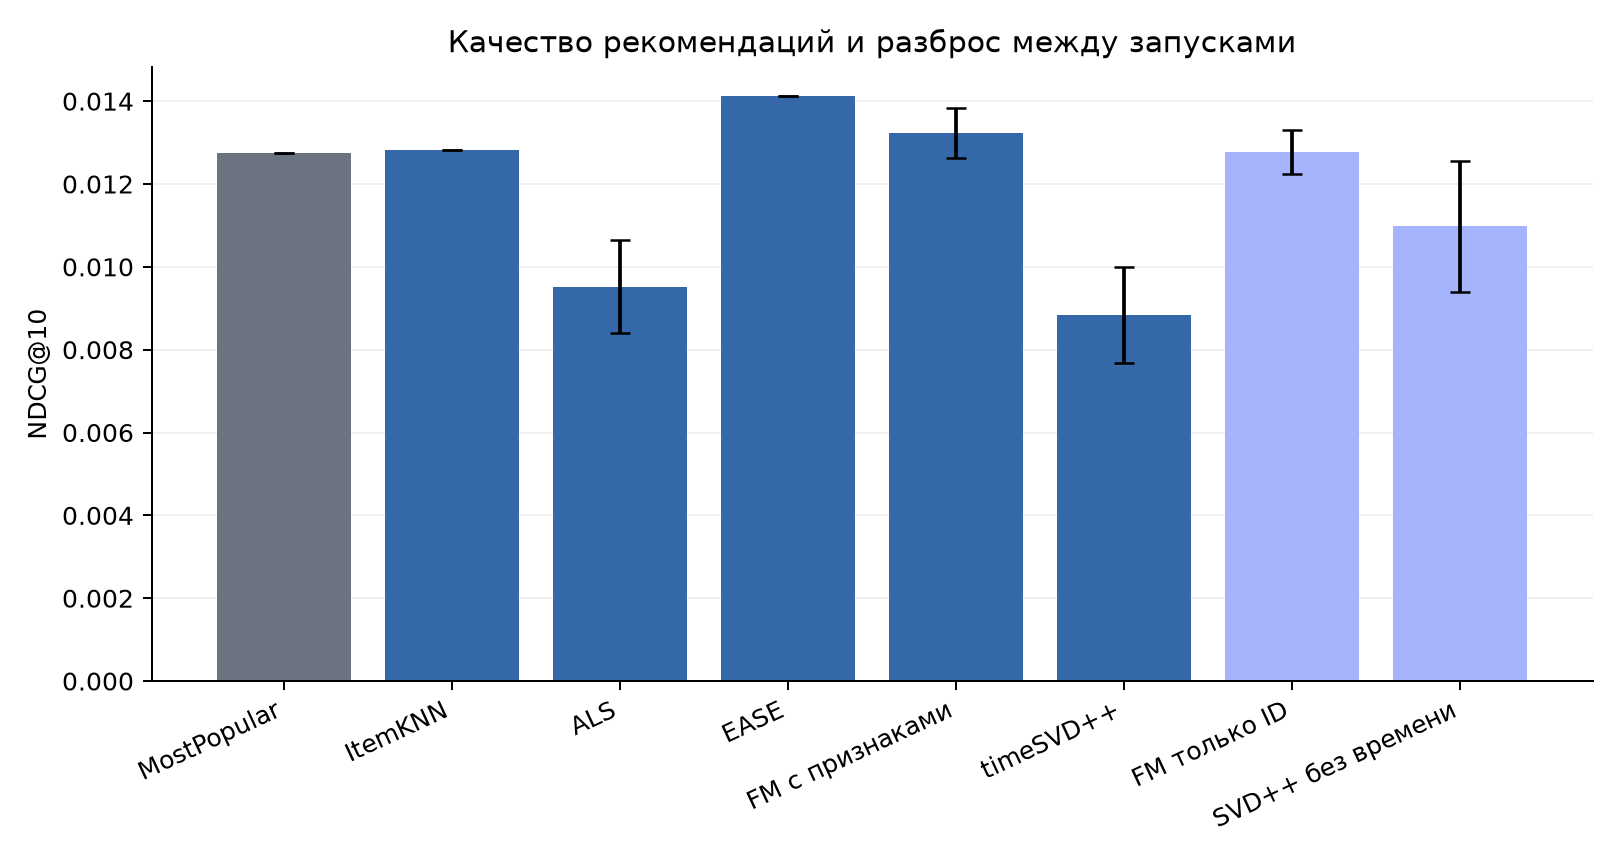

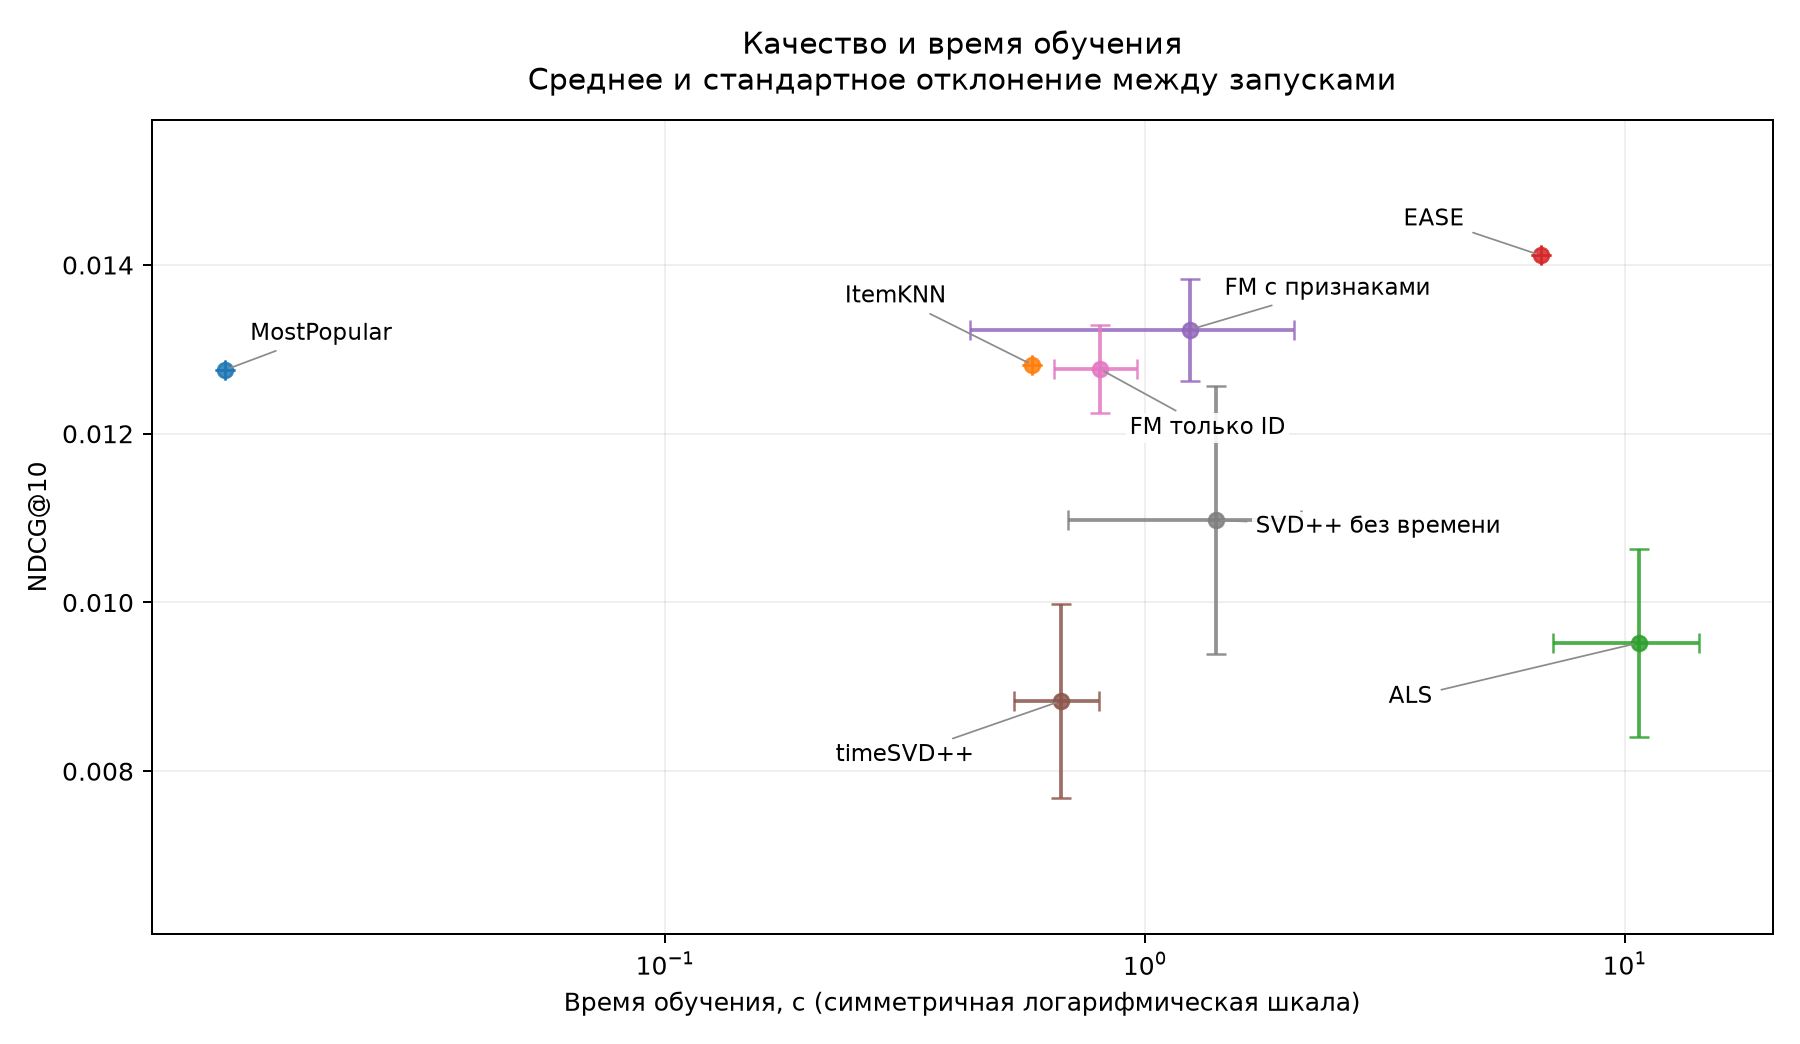

,Модель,"Обучение, с","Рекомендации и метрики, с","Пиковая память, МиБ"
0,MostPopular,0.017,0.413,363.035
1,ItemKNN,0.583,0.821,427.766
2,ALS,10.699,0.623,543.812
3,EASE,6.696,6.027,1240.695
4,FM с признаками,1.239,0.445,407.525
5,timeSVD++,0.668,0.438,427.035
6,FM только ID,0.805,0.484,390.384
7,SVD++ без времени,1.405,0.513,390.302


In [12]:
summary = pd.read_csv(REPORT / 'summary.csv')
table = summary[['label', 'n_seeds', 'ndcg@10_mean', 'ndcg@10_std', 'recall@10_mean',
                 'precision@10_mean', 'map@10_mean', 'catalog_coverage@10_mean']].copy()
table.columns = ['Модель', 'Запуски', 'NDCG@10', 'Отклонение NDCG', 'Recall@10', 'Precision@10', 'MAP@10', 'Покрытие каталога']
table['Параметры'] = [json.dumps(json.loads((RUNS / 'final' / name / '42/run.json').read_text())['parameters'],
                                ensure_ascii=False) for name in summary.model]
display(table.round(6))
print('Число эпох в параметрах показано для начального значения генератора 42. Для остальных запусков оно выбирается отдельно.')
display(Image(filename=str(REPORT / 'ndcg.png')))
display(Image(filename=str(REPORT / 'quality_vs_time.png')))
display(summary[['label', 'fit_seconds_mean', 'test_seconds_mean', 'peak_rss_mib_mean']].rename(
    columns={'label':'Модель', 'fit_seconds_mean':'Обучение, с', 'test_seconds_mean':'Рекомендации и метрики, с', 'peak_rss_mib_mean':'Пиковая память, МиБ'}).round(3))

In [13]:
contrasts = json.loads((REPORT / 'contrasts.json').read_text())
comparison = pd.DataFrame(contrasts)[['first','second','difference','ci95_low','ci95_high','n_users','n_bootstrap']].copy()
labels = dict(zip(summary.model, summary.label))
comparison['first'] = comparison['first'].map(labels)
comparison['second'] = comparison['second'].map(labels)
comparison.columns = ['Первая модель','Вторая модель','Разность NDCG','Нижняя граница','Верхняя граница','Пользователи','Повторы']
display(comparison)
display(Markdown('Метрики пользователя сначала усредняются по трём запускам. Затем 2 000 раз одни и те же пользователи выбираются с возвращением для обеих моделей. Интервалы относятся к данному периоду и настройкам. Дополнительные сравнения приведены без поправки на множественные проверки.'))

,Первая модель,Вторая модель,Разность NDCG,Нижняя граница,Верхняя граница,Пользователи,Повторы
0,timeSVD++,ALS,-0.000690,-0.003893,0.002385,1702,2000
1,timeSVD++,SVD++ без времени,-0.002143,-0.003874,-0.000713,1702,2000
2,FM с признаками,FM только ID,0.000464,-0.000484,0.001371,1702,2000


Метрики пользователя сначала усредняются по трём запускам. Затем 2 000 раз одни и те же пользователи выбираются с возвращением для обеих моделей. Интервалы относятся к данному периоду и настройкам. Дополнительные сравнения приведены без поправки на множественные проверки.

### Пример рекомендаций

Пользователь выбран по фиксированному правилу из группы активности, независимо от качества моделей.
Будущий отзыв служит проверкой попадания. Если отзыва нет, товар не обязательно плохой.

In [14]:
from recsys.core import Model
from recsys.ranking import recommend
example = json.loads((REPORT / 'example_selection.json').read_text())['users'][0]
model = Model.load(RUNS / 'final/ease/42/model.pkl')
items, scores, _ = recommend(model, test_snapshot, np.array([example]), k=10)
truth = set(data.test.loc[(data.test.user == example) & (data.test.rating >= 4), 'item'])
recs = pd.DataFrame({'item':items[0], 'Место':range(1,11), 'Оценка модели':scores[0]})
recs['Попадание'] = recs.item.isin(truth)
print('Внутренний ID пользователя:', example)
display(recs.merge(metadata[['item','asin','title']], on='item')[['Место','asin','title','Оценка модели','Попадание']])
del model
gc.collect()

Внутренний ID пользователя: 10261


,Место,asin,title,Оценка модели,Попадание
0,1,B00IFOTSJW,Snark SN1 Guitar Tuner (Blue),0.002706,False
1,2,B00063678K,M-Audio SP-2 | Universal Sustain Pedal with Piano Style Action for Electronic Keyboards,0.002646,False
2,3,B001PGXKC8,"Planet Waves PW-CGTP-305 Classic Series Instrument Cable with Right Angle Plug, 0.5 feet (3-pack)",0.002421,False
3,4,B00ACGMOA6,VicTsing USB IN-OUT MIDI Cable Converter PC to Music Keyboard Adapter Cord,0.002217,False
4,5,B015I0WXAQ,Samson 2 x MK10 Lightweight Boom Mic Stand #SAMK10 2,0.002104,False
5,6,B000978D58,On-Stage MS7701B Tripod Microphone Boom Stand,0.002048,False
6,7,B000RNB720,Truetone 1 Spot Combo Pack,0.002002,False
7,8,B000CZ0RK6,Behringer FCB1010 Ultra-Flexible MIDI Foot Controller with 2 Expression Pedals and MIDI Merge Function,0.001893,False
8,9,B001UJERGS,Monoprice 104770 10-Feet Premier Series XLR Female to 1/4-Inch TRS Male 16AWG Cable,0.001846,False
9,10,B00005ML71,"Yamaha FC5 Compact Sustain Pedal for Portable Keyboards, black",0.001839,False


15704

## 6. Выводы

Полный отчёт находится в `reports/REPORT.md`, параметры в `reports/selected_parameters.json`.

In [15]:
s = summary.set_index('model')
main = s.loc[list(classes)]
best = main['ndcg@10_mean'].idxmax()
fm_effect = next(c for c in contrasts if c['first']=='fm' and c['second']=='fm_id')
time_effect = next(c for c in contrasts if c['first']=='timesvd' and c['second']=='svdpp')
params = selected[best]['parameters']
display(Markdown(f'''
Лучший NDCG@10 среди пяти методов у {s.loc[best, 'label']}, значение {s.loc[best, 'ndcg@10_mean']:.5f}.
Recall@10 у этой модели {s.loc[best, 'recall@10_mean']:.5f}. Её параметры: `{json.dumps(params)}`.
По Precision@10 выше {s['precision@10_mean'].idxmax()}, по MAP@10 выше {s['map@10_mean'].idxmax()}.

Покрытие каталога у ItemKNN {s.loc['knn','catalog_coverage@10_mean']:.2%},
у EASE {s.loc['ease','catalog_coverage@10_mean']:.2%}, у FM {s.loc['fm','catalog_coverage@10_mean']:.2%}.
У FM рекомендации сосредоточены на небольшом числе товаров.

Метапризнаки FM изменили NDCG на {fm_effect['difference']:.6f}.
95% интервал от {fm_effect['ci95_low']:.6f} до {fm_effect['ci95_high']:.6f}.
Временные компоненты изменили NDCG относительно SVD++ без времени на {time_effect['difference']:.6f},
интервал от {time_effect['ci95_low']:.6f} до {time_effect['ci95_high']:.6f}.
Параметры упрощённых версий унаследованы от полных, число эпох подобрано отдельно.
'''))


Лучший NDCG@10 среди пяти методов у EASE, значение 0.01411.
Recall@10 у этой модели 0.02507. Её параметры: `{"reg": 3000}`.
По Precision@10 выше fm, по MAP@10 выше popular.

Покрытие каталога у ItemKNN 32.16%,
у EASE 14.27%, у FM 0.33%.
У FM рекомендации сосредоточены на небольшом числе товаров.

Метапризнаки FM изменили NDCG на 0.000464.
95% интервал от -0.000484 до 0.001371.
Временные компоненты изменили NDCG относительно SVD++ без времени на -0.002143,
интервал от -0.003874 до -0.000713.
Параметры упрощённых версий унаследованы от полных, число эпох подобрано отдельно.


У выбранных ItemKNN и EASE параметры находятся на верхней границе сетки. Поиск за этими границами не проводился.
ALS, FM и timeSVD++ предсказывают наблюдаемые оценки, а не напрямую порядок первых десяти товаров.
Поэтому низкая ошибка оценок сама по себе не гарантирует лучший NDCG.

Ограничения сравнения:

- Это активные пользователи и фиксированный каталог. На новых пользователях и товарах качество не проверялось.
- Только 57,37% будущих положительных событий выбранных пользователей относятся к доступному каталогу.
- Отзывы не дают полного журнала показов. По этим данным нельзя оценить изменение кликов или продаж.
- Поздние названия и категории используются для отображения. В модели не передаются признаки из будущего.
- Время обучения зависит от выбранного числа эпох. Пиковая память относится ко всему процессу.
- Один период и конечный поиск параметров ограничивают выводы о моделях в целом.

### Источники

[Amazon Reviews 2018](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/),
[Item-based CF](https://www.ra.ethz.ch/CDstore/www10/papers/519/),
[EASE](https://arxiv.org/abs/1905.03375), [FM](https://www.libfm.org/),
[timeSVD++](https://cseweb.ucsd.edu/classes/fa17/cse291-b/reading/p447-koren.pdf),
[полное ранжирование каталога](https://research.google/pubs/on-sampled-metrics-for-item-recommendation/).